# UE01 – Neuronales Netzwerk: MNIST 2

**Name:** Marcus Strohmer  
**Aufgaben:** 18.2.1 bis 18.2.4

Dieses Notebook untersucht die Trainings-History eines neuronalen Netzes, vergleicht Training und Validierung, experimentiert mit `epochs` und `batch_size` und speichert das beste Modell.

In [6]:
# Erklärung zum folgenden Abschnitt
# Path verarbeitet Dateipfade. math wird zum Aufrunden der Batchanzahl verwendet.
# NumPy, Matplotlib und Keras übernehmen Arrays, Diagramme und das neuronale Netz.
# SEED=42 ist ein gewählter Startwert für Zufallszahlengeneratoren.
# set_random_seed setzt die von Keras verwendeten Zufallsquellen für besser vergleichbare Versuche.

from pathlib import Path
import math
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.utils import to_categorical

SEED = 42
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow-Version:", tf.__version__)

TensorFlow-Version: 2.22.0-rc0


## Daten und Modell vorbereiten

Wie in MNIST 1 werden die 28×28-Pixel-Bilder zu Vektoren mit 784 Werten umgeformt und auf den Bereich 0 bis 1 normalisiert. Die Labels werden für `categorical_crossentropy` one-hot-kodiert.

In [8]:
# Erklärung zum folgenden Abschnitt
# Dieses Notebook lädt seine Daten selbst und kann unabhängig von MNIST I gestartet werden.
# _raw bezeichnet hier die ursprünglichen Bilder bzw. ganzzahligen Ziffern.
# reshape macht aus jedem Bild 784 Eingabewerte, float32 und /255.0 skalieren auf 0 bis 1.
# to_categorical erzeugt pro Label einen Vektor mit zehn Einträgen und einer 1.
# Die Form der Trainingsdaten ist (60000,784), die der Trainingslabels (60000,10).

(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = tf.keras.datasets.mnist.load_data()

x_train = x_train_raw.reshape(-1, 784).astype("float32") / 255.0
x_test = x_test_raw.reshape(-1, 784).astype("float32") / 255.0
y_train = to_categorical(y_train_raw, num_classes=10)
y_test = to_categorical(y_test_raw, num_classes=10)

print("Trainingsbilder:", x_train.shape)
print("Trainingslabels:", y_train.shape)
print("Testbilder:     ", x_test.shape)
print("Testlabels:     ", y_test.shape)

Trainingsbilder: (60000, 784)
Trainingslabels: (60000, 10)
Testbilder:      (10000, 784)
Testlabels:      (10000, 10)


In [9]:
# def definiert eine Funktion. Erst create_model(...) führt ihren Inhalt aus.
# clear_session setzt den globalen Keras-Zustand für den Aufbau weiterer Modelle zurück.
# Der Seed unterstützt gleiche Ausgangsbedingungen bei den Versuchen.
# Jeder Aufruf baut ein frisches Netz mit 784 Eingaben, 64 ReLU-Neuronen und 10 Softmax-Ausgaben auf.
# RMSprop optimiert die categorical_crossentropy. accuracy misst den Anteil richtiger Klassen.
# return gibt das neue Modell an den Aufrufer zurück.
# model.summary zeigt die Architektur und die insgesamt 50890 Parameter.

def create_model(seed=SEED):
    """Erstellt das in MNIST 1 vorgegebene Modell mit neuen Gewichten."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    model = Sequential([
        Input(shape=(784,)),
        Dense(64, activation="relu"),
        Dense(10, activation="softmax"),
    ])
    model.compile(
        optimizer="rmsprop",
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

model = create_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

## 18.2.1 Accuracy aus der `fit`-History plotten

`model.fit(...)` liefert ein `History`-Objekt. In dessen Dictionary `history` stehen für jede Epoche unter anderem `loss` und `accuracy`.

In [4]:
# Ein neues Modell wird für 15 Epochen mit Batch-Größe 128 trainiert.
# fit liefert ein History-Objekt zurück. model_history.history ist dessen Dictionary mit Kennzahlen.
# keys() zeigt die verfügbaren Namen, hier insbesondere loss und accuracy.
# verbose=2 gibt je Epoche eine Zusammenfassung aus.

model_training_only = create_model(seed=SEED)
model_history = model_training_only.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=128,
    verbose=2,
)

print("Typ von model_history.history:", type(model_history.history))
print("Verfügbare Keys:", model_history.history.keys())

Epoch 1/15


469/469 - 1s - 3ms/step - accuracy: 0.8940 - loss: 0.3938


Epoch 2/15


469/469 - 1s - 1ms/step - accuracy: 0.9431 - loss: 0.1960


Epoch 3/15


469/469 - 1s - 1ms/step - accuracy: 0.9575 - loss: 0.1477


... (21 outputs left out)

469/469 - 0s - 1ms/step - accuracy: 0.9890 - loss: 0.0425


Epoch 15/15


469/469 - 0s - 1ms/step - accuracy: 0.9903 - loss: 0.0394


Typ von model_history.history: <class 'dict'>
Verfügbare Keys: dict_keys(['accuracy', 'loss'])


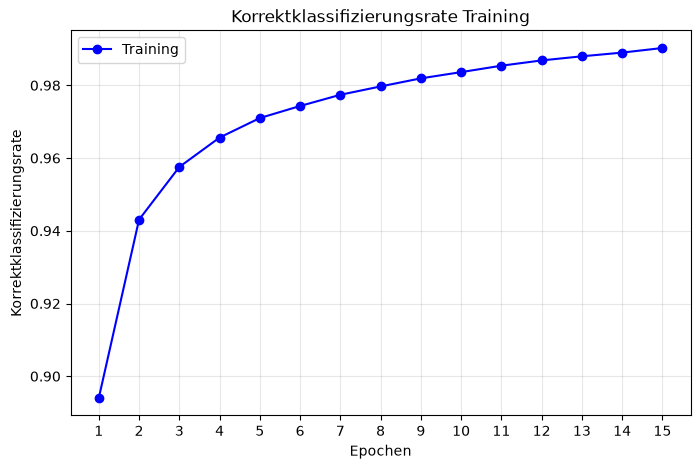

In [5]:
# Der Schlüssel accuracy liefert eine Liste mit der Trainingsgenauigkeit je Epoche.
# len(acc) liefert die Anzahl der tatsächlich ausgeführten Epochen.
# range(1,len(acc)+1) erzeugt die passende Achse von 1 bis einschließlich der letzten Epoche.
# plot erhält x-Werte, y-Werte und die Darstellung b-o: blau, Linie, Kreismarker.
# label legt den Text für legend() fest. xticks zeigt die Epochennummern.

acc = model_history.history["accuracy"]
epochs_axis = range(1, len(acc) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_axis, acc, "b-o", label="Training")
plt.title("Korrektklassifizierungsrate Training")
plt.xlabel("Epochen")
plt.ylabel("Korrektklassifizierungsrate")
plt.xticks(list(epochs_axis))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 18.2.2 Validierungsdaten übergeben und Accuracy vergleichen

Die Validierungsdaten werden als Tupel mit `validation_data=(x_test, y_test)` übergeben. Keras wertet sie nach jeder Epoche aus; die zugehörige Accuracy steht unter dem Key `val_accuracy`. Das Modell wird für einen fairen Lauf neu initialisiert.

In [6]:
# Für diesen Vergleich wird wieder ein frisches Modell erstellt.
# validation_data übergibt Bilder und Labels zur Auswertung nach jeder Epoche.
# Diese Validierung aktualisiert keine Modellgewichte.
# Hier werden die als Testdaten geladenen Beispiele für die Validierung genutzt.
# history enthält dadurch zusätzlich val_loss und val_accuracy.
# math.ceil rundet 60000/128 auf 469 Schritte pro Epoche auf, einschließlich des Restbatches.
# Die Verwendung dieser Daten zur Modellauswahl beeinflusst eine spätere Bewertung auf denselben Beispielen.
#Validierung bedeutet, während des Trainings zu prüfen, wie gut das Modell mit zusätzlichen Beispielen zurechtkommt.

model_with_validation = create_model(seed=SEED)
validation_history = model_with_validation.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=128,
    validation_data=(x_test, y_test),
    verbose=2,
)

print("History-Keys:", validation_history.history.keys())
print("Iterationen pro Epoche:", math.ceil(len(x_train) / 128))

Epoch 1/15


469/469 - 1s - 3ms/step - accuracy: 0.8940 - loss: 0.3938 - val_accuracy: 0.9352 - val_loss: 0.2259


Epoch 2/15


469/469 - 1s - 1ms/step - accuracy: 0.9431 - loss: 0.1960 - val_accuracy: 0.9506 - val_loss: 0.1655


Epoch 3/15


469/469 - 1s - 1ms/step - accuracy: 0.9575 - loss: 0.1477 - val_accuracy: 0.9599 - val_loss: 0.1339


... (21 outputs left out)

469/469 - 1s - 1ms/step - accuracy: 0.9890 - loss: 0.0425 - val_accuracy: 0.9754 - val_loss: 0.0854


Epoch 15/15


469/469 - 1s - 2ms/step - accuracy: 0.9903 - loss: 0.0394 - val_accuracy: 0.9758 - val_loss: 0.0853


History-Keys: dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])
Iterationen pro Epoche: 469


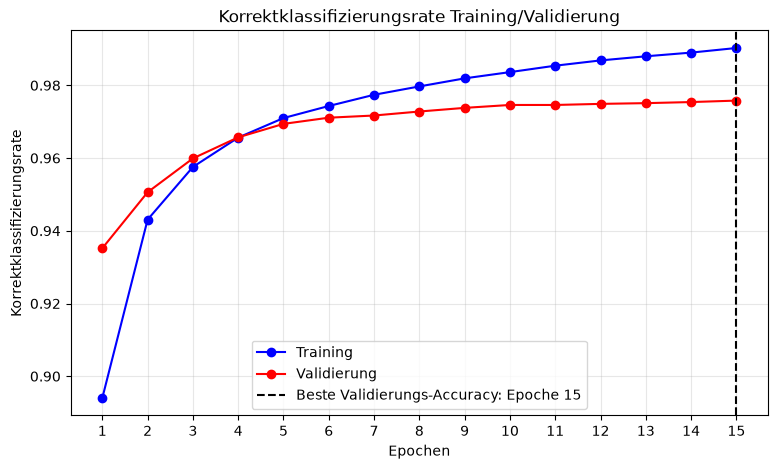

Beste Validierungs-Accuracy: 0.9758 in Epoche 15


In [7]:
# accuracy und val_accuracy liefern die beiden Kurven.
# argmax(val_acc) findet den Listenindex mit der höchsten Validierungsgenauigkeit.
# +1 wandelt den ab null gezählten Index in die Epochennummer ab eins um.
# axvline markiert diese Epoche im Diagramm.
# Diese Markierung dient der Darstellung. Sie lädt hier keine früheren Modellgewichte.
# Wenn die Trainingsleistung weiter steigt und die Validierungsleistung nachlässt, deutet das auf Überanpassung hin.

train_acc = validation_history.history["accuracy"]
val_acc = validation_history.history["val_accuracy"]
epochs_axis = range(1, len(train_acc) + 1)
best_acc_epoch = int(np.argmax(val_acc)) + 1

plt.figure(figsize=(9, 5))
plt.plot(epochs_axis, train_acc, "b-o", label="Training")
plt.plot(epochs_axis, val_acc, "r-o", label="Validierung")
plt.axvline(best_acc_epoch, color="black", linestyle="--", label=f"Beste Validierungs-Accuracy: Epoche {best_acc_epoch}")
plt.title("Korrektklassifizierungsrate Training/Validierung")
plt.xlabel("Epochen")
plt.ylabel("Korrektklassifizierungsrate")
plt.xticks(list(epochs_axis))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

print(f"Beste Validierungs-Accuracy: {max(val_acc):.4f} in Epoche {best_acc_epoch}")

## 18.2.3 Hyperparameter vergleichen: `epochs` und `batch_size`

Drei Kombinationen werden jeweils mit frisch initialisierten Gewichten trainiert. Verglichen werden `loss` und `val_loss`. Als beste Variante gilt hier diejenige mit dem niedrigsten beobachteten Validierungsverlust.

In [8]:
# configurations ist eine Liste von Dictionaries mit drei gewählten Hyperparameterkombinationen.
# epochs und batch_size werden vor dem Training festgelegt, Gewichte werden währenddessen gelernt.
# enumerate(...,start=1) liefert Versuchsnummer und jeweilige Konfiguration.
# Jeder Versuch beginnt mit einem neu erzeugten Modell.
# config["epochs"] und config["batch_size"] lesen die Einstellungen aus dem Dictionary.
# EarlyStopping beobachtet hier val_loss. restore_best_weights=True stellt am Ende die besten Gewichte wieder her.
# patience entspricht der gesamten Epochenzahl. Daher beendet dieser Callback die Versuche hier nicht vorzeitig.
# Er wird in diesem Code vor allem zum Wiederherstellen der besten Gewichte verwendet.
# min(history["val_loss"]) ermittelt den kleinsten Verlust des Versuchs.
# argmin findet dessen Position, +1 macht daraus die Epochennummer.
# append speichert Konfiguration, Verlauf, Modell und Kennwerte als neues Dictionary in der Ergebnisliste.
# Hier ändern sich Epochen und Batch-Größe gemeinsam. Der Vergleich betrifft die gesamten Kombinationen.

configurations = [
    {"epochs": 8, "batch_size": 32},
    {"epochs": 10, "batch_size": 64},
    {"epochs": 15, "batch_size": 128},
]

experiment_results = []
for index, config in enumerate(configurations, start=1):
    print(f"\nExperiment {index}: epochs={config['epochs']}, batch_size={config['batch_size']}")
    experiment_model = create_model(seed=SEED)
    experiment_history = experiment_model.fit(
        x_train,
        y_train,
        epochs=config["epochs"],
        batch_size=config["batch_size"],
        validation_data=(x_test, y_test),
        callbacks=[tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=config["epochs"],
            restore_best_weights=True,
        )],
        verbose=0,
    )
    min_val_loss = float(min(experiment_history.history["val_loss"]))
    best_epoch = int(np.argmin(experiment_history.history["val_loss"])) + 1
    experiment_results.append({
        "config": config,
        "history": experiment_history,
        "model": experiment_model,
        "min_val_loss": min_val_loss,
        "best_epoch": best_epoch,
    })
    print(f"Niedrigster val_loss: {min_val_loss:.4f} in Epoche {best_epoch}")


Experiment 1: epochs=8, batch_size=32


Niedrigster val_loss: 0.1030 in Epoche 8

Experiment 2: epochs=10, batch_size=64


Niedrigster val_loss: 0.0914 in Epoche 8

Experiment 3: epochs=15, batch_size=128


Niedrigster val_loss: 0.0850 in Epoche 12


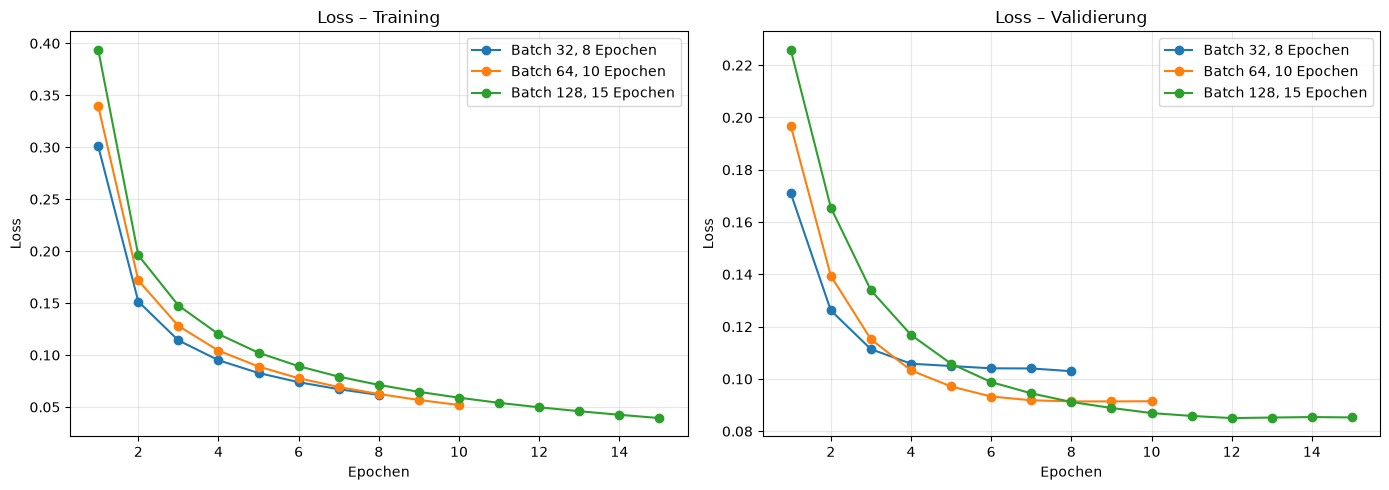

In [9]:
# subplots(1,2) erstellt zwei Achsen: links Trainingsverlust, rechts Validierungsverlust.
# Die Schleife zeichnet für jede Konfiguration eine Kurve auf jeder Achse.
# axes[0] und axes[1] wählen die Diagramme aus.
# Jeder Verlauf bekommt seine eigene Epochenachse, weil die Versuche unterschiedlich lange laufen.
# label und legend machen sichtbar, welche Kurve zu welcher Kombination gehört.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for result in experiment_results:
    config = result["config"]
    history = result["history"].history
    epochs_axis = range(1, len(history["loss"]) + 1)
    label = f"Batch {config['batch_size']}, {config['epochs']} Epochen"
    axes[0].plot(epochs_axis, history["loss"], marker="o", label=label)
    axes[1].plot(epochs_axis, history["val_loss"], marker="o", label=label)

axes[0].set_title("Loss – Training")
axes[1].set_title("Loss – Validierung")
for axis in axes:
    axis.set_xlabel("Epochen")
    axis.set_ylabel("Loss")
    axis.grid(alpha=0.3)
    axis.legend()

plt.tight_layout()
plt.show()

In [10]:
# min(...,key=...) wählt das Ergebnis mit dem kleinsten gespeicherten min_val_loss.
# lambda result: result["min_val_loss"] ist eine kurze Funktion, die den Vergleichswert liefert.
# best_model verweist auf das Modell dieses Versuchs mit den wiederhergestellten besten Gewichten.
# evaluate berechnet dessen Loss und Accuracy.
# Die verwendeten x_test/y_test haben bereits zur Validierung und Auswahl beigetragen.
# Damit ist diese Zahl eine Bewertung auf den Auswahldaten. Für eine unabhängige Abschlussbewertung braucht man zusätzliche zurückgehaltene Daten.

best_result = min(experiment_results, key=lambda result: result["min_val_loss"])
best_config = best_result["config"]
best_model = best_result["model"]

print("Beste untersuchte Konfiguration:")
print(f"  epochs={best_config['epochs']}")
print(f"  batch_size={best_config['batch_size']}")
print(f"  niedrigster val_loss={best_result['min_val_loss']:.4f}")
print(f"  beste Epoche={best_result['best_epoch']}")

test_loss, test_accuracy = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Test-Loss mit den Gewichten der besten Epoche: {test_loss:.4f}")
print(f"Test-Accuracy mit den Gewichten der besten Epoche: {test_accuracy:.4f} ({test_accuracy:.2%})")

Beste untersuchte Konfiguration:
  epochs=15
  batch_size=128
  niedrigster val_loss=0.0850
  beste Epoche=12


Test-Loss des Modells am Trainingsende: 0.0853
Test-Accuracy des Modells am Trainingsende: 0.9758 (97.58%)


### Interpretation

Der Trainingsverlust sinkt normalerweise kontinuierlich. Sinkt der Validierungsverlust zunächst und steigt später wieder, während der Trainingsverlust weiter fällt, ist das ein Hinweis auf Überanpassung. Daher ist nicht automatisch die Variante mit den meisten Epochen am besten. Ein separates Validierungsset wäre in einem realen Projekt sauberer als die wiederholte Verwendung des Testsets; hier wird das Testset entsprechend der Aufgabenstellung als Validierungsdatensatz eingesetzt.

## 18.2.4 Modell speichern und wieder laden

Das ausgewählte Modell wird im aktuellen Ordner im aktuellen `.keras`-Format gespeichert. Anschließend wird es zur direkten Kontrolle erneut geladen. Das separate Notebook `UE01_MNIST2_Modell_laden_Strohmer.ipynb` demonstriert das Laden in einem neuen Notebook.

In [11]:
# Path.cwd() liefert den aktuellen Arbeitsordner des Notebooks.
# Der Operator / verbindet diesen Ordner mit dem Dateinamen.
# save speichert Architektur, Gewichte und Trainingskonfiguration einschließlich Optimiererzustand im .keras-Format.
# stat().st_size liefert die Dateigröße in Bytes, /1024 rechnet sie in KiB um.
# Das separate Lade-Notebook erwartet diese Datei in seinem aktuellen Arbeitsordner.

MODEL_PATH = Path.cwd() / "mnist2_best_model.keras"
best_model.save(MODEL_PATH)
print("Modell gespeichert unter:", MODEL_PATH)
print(f"Dateigröße: {MODEL_PATH.stat().st_size / 1024:.1f} KiB")

Modell gespeichert unter: C:\Users\marcu\DSAI\SJ2627_5CHIT_DSAI_Strohmer\UE01\mnist2_best_model.keras
Dateigröße: 416.6 KiB


In [12]:
# load_model rekonstruiert das zuvor gespeicherte Modell.
# [:10] wählt die ersten zehn Testbilder als Batch.
# Beide Modelle liefern dafür Wahrscheinlichkeiten, die assert_allclose vergleicht.
# rtol und atol erlauben geringe numerische Abweichungen.
# Bei zu großen Unterschieden wird ein Fehler ausgelöst.
# Die abschließende evaluate-Abfrage zeigt die Leistung des geladenen Modells.

loaded_model = tf.keras.models.load_model(MODEL_PATH)
original_prediction = best_model.predict(x_test[:10], verbose=0)
loaded_prediction = loaded_model.predict(x_test[:10], verbose=0)
np.testing.assert_allclose(original_prediction, loaded_prediction, rtol=1e-6, atol=1e-6)

loaded_loss, loaded_accuracy = loaded_model.evaluate(x_test, y_test, verbose=0)
print("Speichern und Laden erfolgreich – Vorhersagen sind identisch.")
print(f"Geladenes Modell – Loss: {loaded_loss:.4f}, Accuracy: {loaded_accuracy:.4f} ({loaded_accuracy:.2%})")

Speichern und Laden erfolgreich – Vorhersagen sind identisch.
Geladenes Modell – Loss: 0.0853, Accuracy: 0.9758 (97.58%)


## Fazit

Die `fit`-History macht den Verlauf von Accuracy und Loss sichtbar. Durch den Vergleich mit Validierungswerten lässt sich Überanpassung erkennen. `epochs` bestimmt die Anzahl vollständiger Durchläufe durch den Datensatz; `batch_size` bestimmt, nach wie vielen Beispielen die Gewichte aktualisiert werden. Das gespeicherte `.keras`-Modell enthält Architektur, Gewichte und Trainingskonfiguration und kann ohne erneutes Training geladen werden.